# Comprehensive Exploratory Research Analysis & Multi-Horizon Machine Learning Forecasting of Delhi Air Quality Index (AQI)



## Chapter 1: Problem Formulation & Indian CPCB NAQI Standard


In [ ]:
# Setup plotting, environment, and library imports
import os
import sys
import tempfile
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

os.environ["MPLCONFIGDIR"] = os.path.join(tempfile.gettempdir(), "matplotlib_aqi")
warnings.filterwarnings("ignore")

# Style configurations for publication-grade figures
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["axes.linewidth"] = 0.8
plt.rcParams["grid.color"] = "#eeeeee"
plt.rcParams["grid.linestyle"] = "--"
plt.rcParams["figure.dpi"] = 100

# Import official CPCB calculator module from src.data
from src.data.cpcb_calculator import (
    CPCB_BREAKPOINTS,
    AQI_CATEGORIES,
    calculate_sub_index,
    calculate_overall_aqi,
    get_aqi_category,
    get_aqi_color,
    get_aqi_metadata
)

def get_aqi_category_and_color(aqi_val):
    return get_aqi_category(aqi_val), get_aqi_color(aqi_val)

print("Libraries and CPCB NAQI Calculator successfully imported.")

Libraries and CPCB NAQI Calculator successfully imported.


In [ ]:
# Display the official Indian CPCB NAQI Breakpoint Table
records = []
for p, brackets in CPCB_BREAKPOINTS.items():
    unit = "mg/m³" if p == "CO" else "µg/m³"
    row = {"Pollutant": f"{p} ({unit})"}
    for idx, (b_lo, b_hi, i_lo, i_hi) in enumerate(brackets):
        cat_name = AQI_CATEGORIES[idx]["name"]
        row[f"{cat_name} ({int(i_lo)}-{int(i_hi)})"] = f"{b_lo} - {b_hi}"
    records.append(row)

df_breakpoints = pd.DataFrame(records)
print("=== CPCB National Air Quality Index (NAQI) Breakpoint Table ===")
display_cols = ["Pollutant"] + [f"{c['name']} ({int(c['min_aqi'])}-{int(c['max_aqi']) if c['max_aqi']<=500 else '500+'})" for c in AQI_CATEGORIES]
df_breakpoints.columns = display_cols
pd.set_option("display.max_columns", 10)
pd.set_option("display.width", 1000)
print(df_breakpoints.to_string(index=False))

=== CPCB National Air Quality Index (NAQI) Breakpoint Table ===
    Pollutant Good (0-50) Satisfactory (51-100) Moderate (101-200) Poor (201-300) Very Poor (301-400) Severe (401-500+)
PM2.5 (µg/m³)  0.0 - 30.0           30.0 - 60.0        60.0 - 90.0   90.0 - 120.0       120.0 - 250.0     250.0 - 380.0
 PM10 (µg/m³)  0.0 - 50.0          50.0 - 100.0      100.0 - 250.0  250.0 - 350.0       350.0 - 430.0     430.0 - 510.0
  NO2 (µg/m³)  0.0 - 40.0           40.0 - 80.0       80.0 - 180.0  180.0 - 280.0       280.0 - 400.0     400.0 - 500.0
  SO2 (µg/m³)  0.0 - 40.0           40.0 - 80.0       80.0 - 380.0  380.0 - 800.0      800.0 - 1600.0   1600.0 - 2000.0
   CO (mg/m³)   0.0 - 1.0             1.0 - 2.0         2.0 - 10.0    10.0 - 17.0         17.0 - 34.0       34.0 - 50.0
   O3 (µg/m³)  0.0 - 50.0          50.0 - 100.0      100.0 - 168.0  168.0 - 208.0       208.0 - 748.0    748.0 - 1000.0
  NH3 (µg/m³) 0.0 - 200.0         200.0 - 400.0      400.0 - 800.0 800.0 - 1200.0     1200.0 - 1


Demonstration of Multi-Pollutant Aggregation:
Input Concentrations: {'PM2.5': 142.5, 'PM10': 265.0, 'NO2': 68.4, 'SO2': 15.2, 'CO': 1.8}
>> Calculated AQI: 318.0
>> Dominant Pollutant: PM2.5
>> Category: Very Poor (Color: #FF0000)
>> Health Statement: Respiratory illness on prolonged exposure.


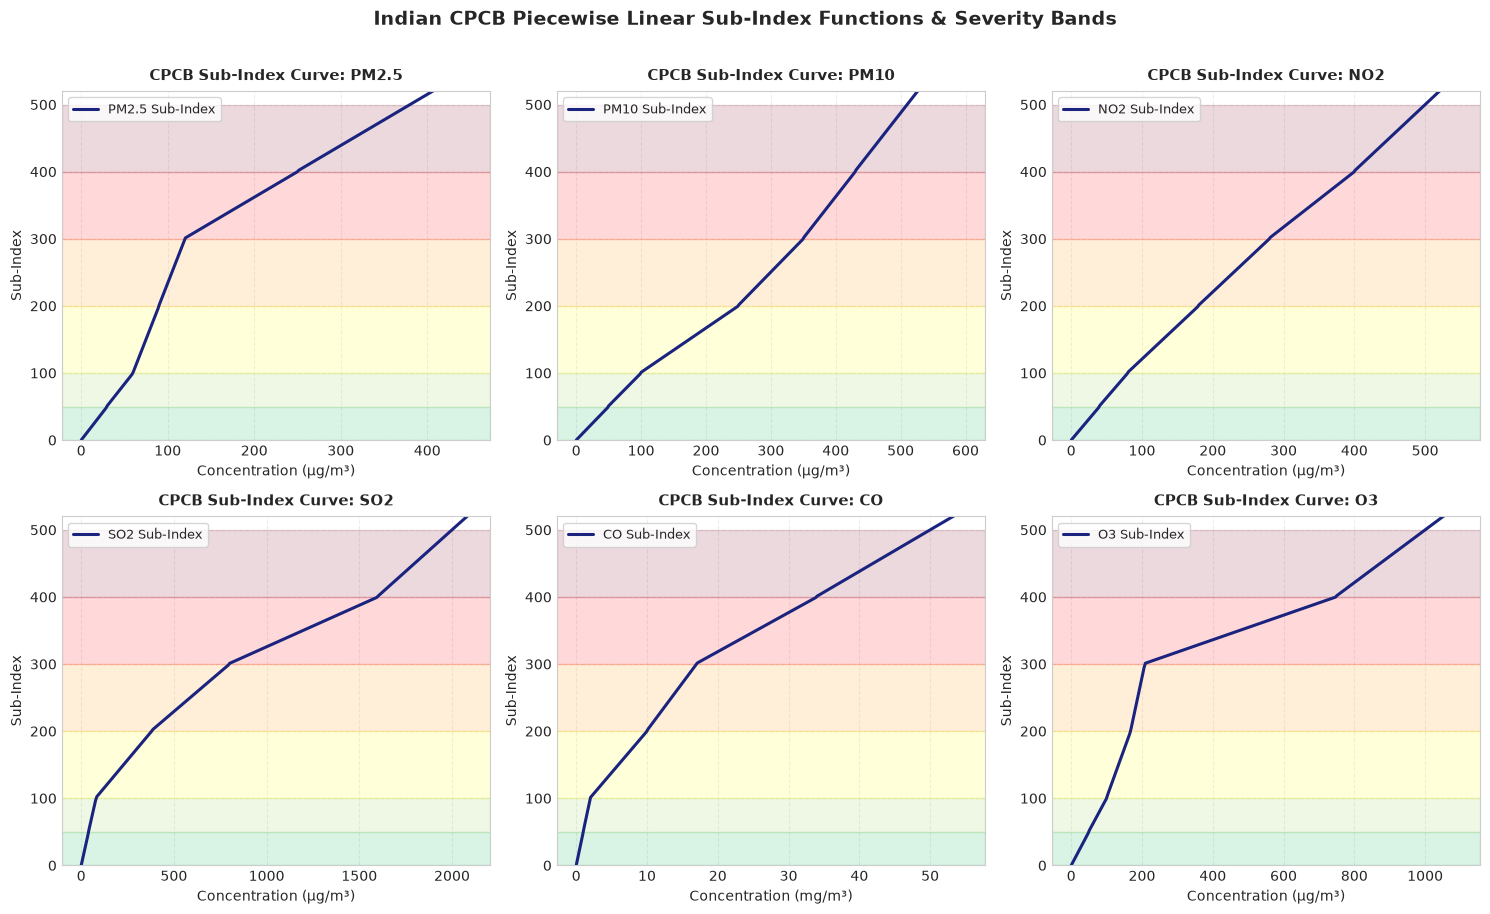

In [ ]:
# Verify CPCB piecewise linear response curves across pollutants
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

pollutants = ["PM2.5", "PM10", "NO2", "SO2", "CO", "O3"]
max_concs = {"PM2.5": 450, "PM10": 600, "NO2": 550, "SO2": 2100, "CO": 55, "O3": 1100}

cat_colors = [c["color"] for c in AQI_CATEGORIES]
cat_bounds = [0, 50, 100, 200, 300, 400, 500]

for idx, p in enumerate(pollutants):
    ax = axes[idx]
    c_vals = np.linspace(0, max_concs[p], 300)
    sub_indices = [calculate_sub_index(p, val, round_result=False) for val in c_vals]

    # Plot category background spans
    for c_idx in range(len(AQI_CATEGORIES)):
        y_low = cat_bounds[c_idx]
        y_high = cat_bounds[c_idx+1]
        ax.axhspan(y_low, y_high, color=cat_colors[c_idx], alpha=0.15)

    ax.plot(c_vals, sub_indices, color="#1a237e", lw=2.2, label=f"{p} Sub-Index")
    unit = "mg/m³" if p == "CO" else "µg/m³"
    ax.set_title(f"CPCB Sub-Index Curve: {p}", fontsize=11, fontweight="bold", pad=8)
    ax.set_xlabel(f"Concentration ({unit})", fontsize=10)
    ax.set_ylabel("Sub-Index", fontsize=10)
    ax.set_ylim(0, 520)
    ax.legend(loc="upper left", frameon=True, fontsize=9)

plt.suptitle("Indian CPCB Piecewise Linear Sub-Index Functions & Severity Bands", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# Demonstrate sample overall AQI calculation
sample_measurements = {"PM2.5": 142.5, "PM10": 265.0, "NO2": 68.4, "SO2": 15.2, "CO": 1.8}
sample_result = calculate_overall_aqi(sample_measurements)
sample_meta = get_aqi_metadata(sample_result["aqi"])
print("\nDemonstration of Multi-Pollutant Aggregation:")
print(f"Input Concentrations: {sample_measurements}")
print(f">> Calculated AQI: {sample_result['aqi']}")
print(f">> Dominant Pollutant: {sample_result['dominant_pollutant']}")
print(f">> Category: {sample_result['category']} (Color: {sample_result['color']})")
print(f">> Health Statement: {sample_meta['health_statement']}")

## Chapter 2: Secure Data Loading & Cryptographic Verification

### 2.1 Cryptographic Data Integrity

In [ ]:
# Cryptographic Verification of Raw CPCB Data
import hashlib
from src.data.ingestion import EXPECTED_HISTORICAL_SHA256, compute_sha256, verify_data_integrity

raw_path = os.path.join("data", "raw", "delhi_cpcb_historical.csv")
expected_sha256 = EXPECTED_HISTORICAL_SHA256

hasher = hashlib.sha256()
with open(raw_path, "rb") as f:
    while chunk := f.read(65536):
        hasher.update(chunk)
computed_sha256 = hasher.hexdigest()

print("=== Cryptographic Data Integrity Verification ===")
print(f"File Path: {raw_path}")
print(f"Expected SHA-256: {expected_sha256}")
print(f"Computed SHA-256: {computed_sha256}")
assert computed_sha256 == expected_sha256, "Cryptographic integrity failure: Hash mismatch!"
assert verify_data_integrity(raw_path, expected_sha256), "Ingestion module verification failed!"
print("STATUS: Cryptographic verification PASSED. Dataset authenticity and integrity verified.")

# Load raw dataset and display schema
df_raw = pd.read_csv(raw_path)
print(f"\nRaw Dataset Dimensions: {df_raw.shape[0]} rows × {df_raw.shape[1]} columns")
print(f"Date Coverage: {df_raw['Date'].min()} to {df_raw['Date'].max()}")
print("\nColumn Data Types and Non-Null Counts:")
print(df_raw.info())

=== Cryptographic Data Integrity Verification ===
File Path: data\raw\delhi_cpcb_historical.csv
Expected SHA-256: c30b58b76c7f6bd83073f3690cdc4ff7c76b8626ddc31f94bbee3743952d1397
Computed SHA-256: c30b58b76c7f6bd83073f3690cdc4ff7c76b8626ddc31f94bbee3743952d1397
STATUS: Cryptographic verification PASSED. Dataset authenticity and integrity verified.

Raw Dataset Dimensions: 2009 rows × 11 columns
Date Coverage: 2015-01-01 to 2020-07-01

Column Data Types and Non-Null Counts:
<class 'pandas.DataFrame'>
RangeIndex: 2009 entries, 0 to 2008
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        2009 non-null   str    
 1   Date        2009 non-null   str    
 2   PM2.5       2007 non-null   float64
 3   PM10        1932 non-null   float64
 4   NO2         2007 non-null   float64
 5   SO2         1899 non-null   float64
 6   CO          2009 non-null   float64
 7   O3          1925 non-null   float64
 8   NH3        

In [ ]:
# Inspect Processed Dataset
processed_path = os.path.join("data", "processed", "delhi_aqi_daily.csv")
df_daily = pd.read_csv(processed_path)
df_daily["Date"] = pd.to_datetime(df_daily["Date"])
df_daily = df_daily.sort_values("Date").reset_index(drop=True)

print(f"=== Processed Dataset Inspection ===")
print(f"File Path: {processed_path}")
print(f"Dimensions: {df_daily.shape[0]} daily records × {df_daily.shape[1]} columns")
print(f"Temporal Continuity: {df_daily['Date'].min().strftime('%Y-%m-%d')} to {df_daily['Date'].max().strftime('%Y-%m-%d')}")
print(f"Total Days in Time-Series: {len(df_daily)}")

# Check for nulls in critical columns
critical_cols = ["PM2.5", "PM10", "NO2", "SO2", "CO", "O3", "Calculated_AQI", "Dominant_Pollutant", "AQI_Category"]
null_counts = df_daily[critical_cols].isnull().sum()
print("\nNull Value Audit in Critical Engineered Fields:")
print(null_counts)
assert null_counts.sum() == 0, "Null values detected in processed fields!"
print("STATUS: Processed dataset is clean, complete, and fully continuous.")

# Preview sample records
display_cols = ["Date", "PM2.5", "PM10", "NO2", "CO", "Calculated_AQI", "Dominant_Pollutant", "AQI_Category"]
print("\nFirst 5 Processed Records:")
print(df_daily[display_cols].head())
print("\nLast 5 Processed Records:")
print(df_daily[display_cols].tail())

=== Processed Dataset Inspection ===
File Path: data\processed\delhi_aqi_daily.csv
Dimensions: 2009 daily records × 30 columns
Temporal Continuity: 2015-01-01 to 2020-07-01
Total Days in Time-Series: 2009

Null Value Audit in Critical Engineered Fields:
PM2.5                 0
PM10                  0
NO2                   0
SO2                   0
CO                    0
O3                    0
Calculated_AQI        0
Dominant_Pollutant    0
AQI_Category          0
dtype: int64
STATUS: Processed dataset is clean, complete, and fully continuous.

First 5 Processed Records:
        Date   PM2.5    PM10    NO2    CO  Calculated_AQI Dominant_Pollutant AQI_Category
0 2015-01-01  313.22  607.98  55.00  9.72           621.0               PM10       Severe
1 2015-01-02  186.18  269.55  45.00  7.50           351.0              PM2.5    Very Poor
2 2015-01-03  216.43  359.73  84.57  3.37           374.0              PM2.5    Very Poor
3 2015-01-04  244.79  364.83  70.13  2.96           396.0    

## Chapter 3: Exploratory Data Analysis (EDA) of Delhi Atmospheric Dynamics

### 3.1 Atmospheric Mechanisms and Physics

* **1. Winter Atmospheric Inversion (Nov – Jan)**
* **2. Summer Crustal Aerosol Influx (Apr – Jun)**
* **3. Monsoon Wet Scavenging (Jul – Sep)**

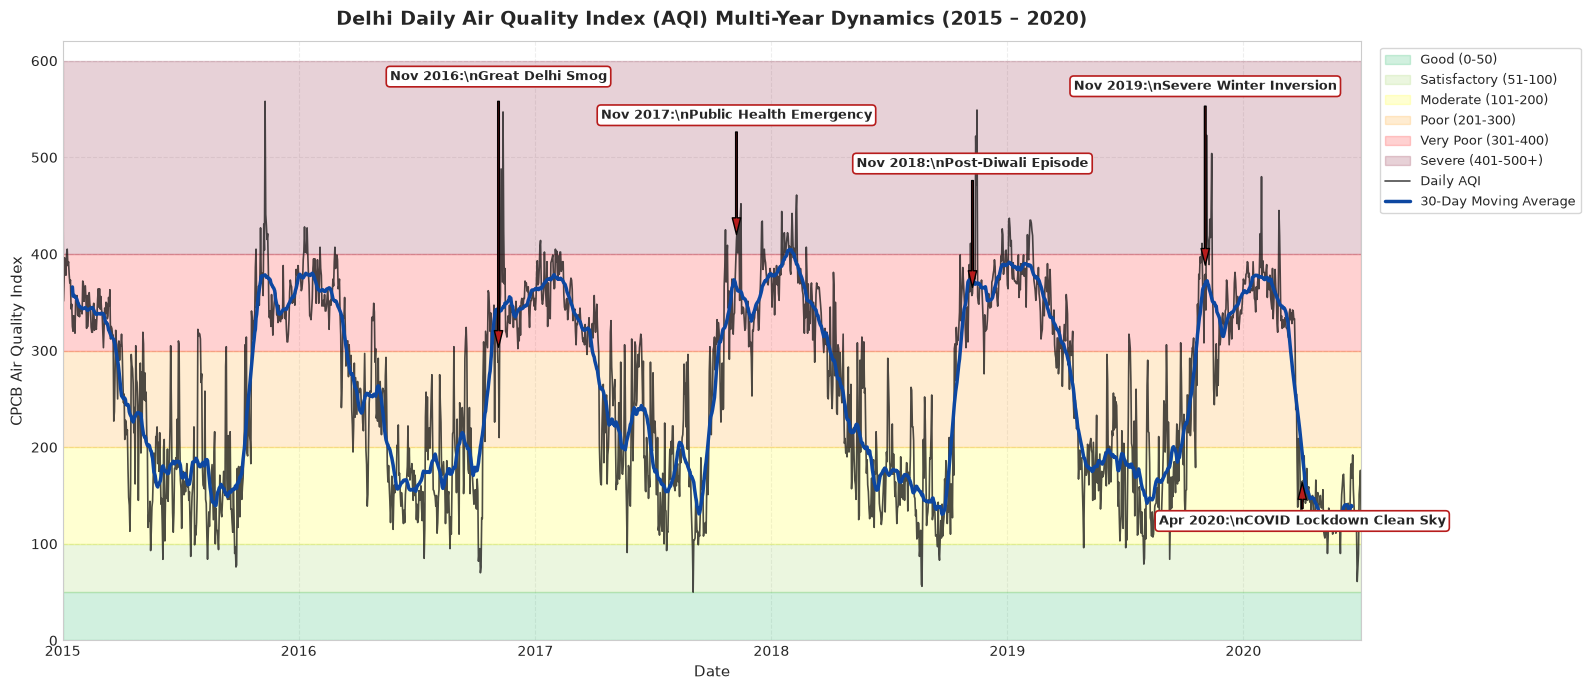

In [ ]:
# Figure 1: Multi-Year Daily AQI Timeline with CPCB Severity Bands (2015 - 2020)
fig, ax = plt.subplots(figsize=(16, 7))

# Shaded background category zones
cat_bands = [
    (0, 50, "#00B050", "Good (0-50)"),
    (50, 100, "#92D050", "Satisfactory (51-100)"),
    (100, 200, "#FFFF00", "Moderate (101-200)"),
    (200, 300, "#FF9900", "Poor (201-300)"),
    (300, 400, "#FF0000", "Very Poor (301-400)"),
    (400, 600, "#7E0023", "Severe (401-500+)")
]

for y_lo, y_hi, color, label in cat_bands:
    ax.axhspan(y_lo, y_hi, color=color, alpha=0.18, label=label)

# Plot daily calculated AQI
ax.plot(df_daily["Date"], df_daily["Calculated_AQI"], color="#111111", lw=1.2, alpha=0.75, label="Daily AQI")

# Plot 30-day moving average
df_daily["AQI_MA30"] = df_daily["Calculated_AQI"].rolling(30, center=True).mean()
ax.plot(df_daily["Date"], df_daily["AQI_MA30"], color="#0d47a1", lw=2.5, label="30-Day Moving Average")

# Annotate historical landmark atmospheric events
events = [
    ("2016-11-05", 580, "Nov 2016:\\nGreat Delhi Smog"),
    ("2017-11-08", 540, "Nov 2017:\\nPublic Health Emergency"),
    ("2018-11-08", 490, "Nov 2018:\\nPost-Diwali Episode"),
    ("2019-11-03", 570, "Nov 2019:\\nSevere Winter Inversion"),
    ("2020-04-01", 120, "Apr 2020:\\nCOVID Lockdown Clean Sky")
]

for date_str, y_pos, text in events:
    event_date = pd.to_datetime(date_str)
    if event_date in df_daily["Date"].values:
        actual_val = df_daily.loc[df_daily["Date"] == event_date, "Calculated_AQI"].values[0]
        ax.annotate(
            text,
            xy=(matplotlib.dates.date2num(event_date), actual_val),
            xytext=(matplotlib.dates.date2num(event_date), y_pos),
            arrowprops=dict(facecolor="#b71c1c", shrink=0.05, width=1.2, headwidth=6),
            fontsize=9,
            fontweight="bold",
            ha="center",
            bbox=dict(boxstyle="round,pad=0.3", fc="#ffffff", ec="#b71c1c", lw=1.2)
        )

ax.set_title("Delhi Daily Air Quality Index (AQI) Multi-Year Dynamics (2015 – 2020)", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Date", fontsize=11)
ax.set_ylabel("CPCB Air Quality Index", fontsize=11)
ax.set_ylim(0, 620)
ax.set_xlim(df_daily["Date"].min(), df_daily["Date"].max())
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=True, fontsize=9)

plt.tight_layout()
plt.show()

=== Monthly Seasonal Air Quality Summary Statistics ===
Month  Mean_AQI  Median_AQI  Std_AQI  Pct_Severe  Pct_VeryPoor_or_Worse
  Jan     377.0       376.0     31.3        15.6                  100.0
  Feb     366.7       364.0     29.8        12.9                  100.0
  Mar     311.5       320.0     46.6         0.0                   75.3
  Apr     234.5       241.0     66.6         0.0                   20.0
  May     186.8       174.5     56.0         0.0                    3.8
  Jun     179.3       171.0     53.5         0.0                    5.0
  Jul     168.7       156.5     51.4         0.0                    3.8
  Aug     169.0       159.0     54.8         0.0                    1.9
  Sep     168.0       156.5     57.2         0.0                    4.7
  Oct     274.0       303.0     86.3         2.6                   54.2
  Nov     360.2       347.0     57.5        20.0                   92.7
  Dec     354.1       352.0     27.7         4.5                   98.7


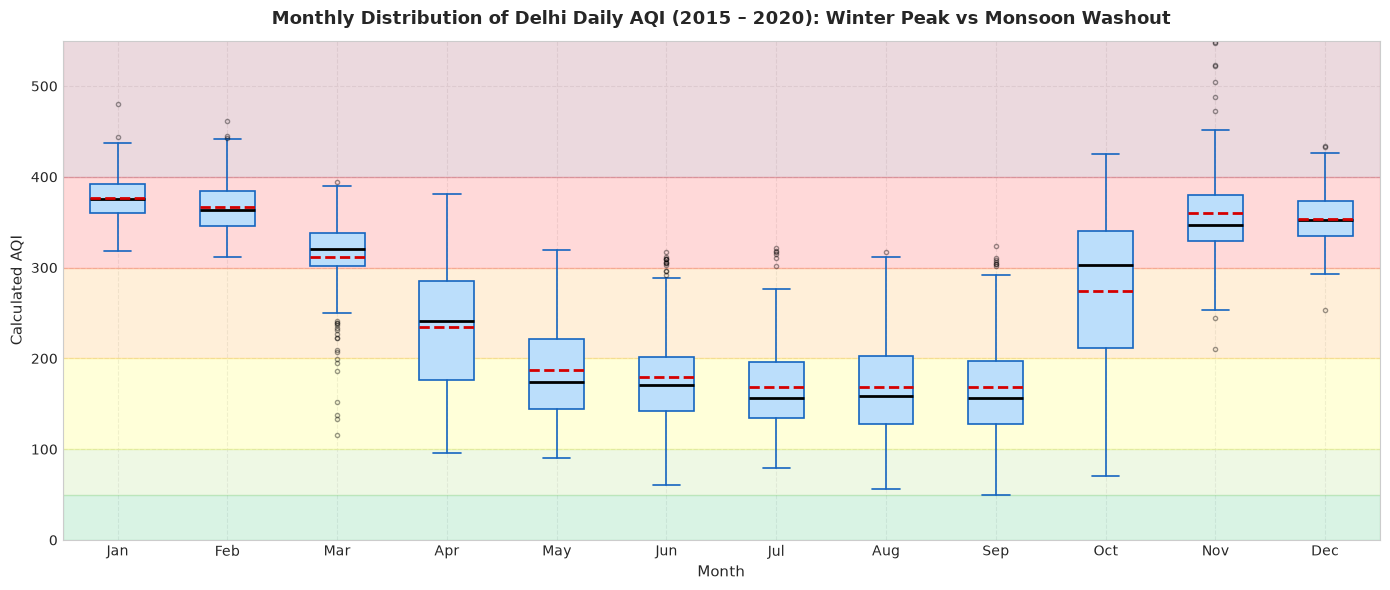

In [ ]:
# Figure 2: Seasonal Cycle & Monthly Boxplot Distribution
fig, ax = plt.subplots(figsize=(14, 6))

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
df_daily["Month_Name"] = df_daily["Date"].dt.month.map(lambda m: month_names[m-1])

# Prepare monthly data
monthly_aqi = [df_daily[df_daily["Date"].dt.month == m]["Calculated_AQI"].values for m in range(1, 13)]

# Plot background category zones
for y_lo, y_hi, color, label in cat_bands:
    ax.axhspan(y_lo, y_hi, color=color, alpha=0.15)

box = ax.boxplot(
    monthly_aqi,
    tick_labels=month_names,
    patch_artist=True,
    showmeans=True,
    meanline=True,
    medianprops=dict(color="#000000", lw=2.0),
    meanprops=dict(color="#d50000", lw=2.0, ls="--"),
    boxprops=dict(facecolor="#bbdefb", color="#1565c0", lw=1.2),
    whiskerprops=dict(color="#1565c0", lw=1.2),
    capprops=dict(color="#1565c0", lw=1.2),
    flierprops=dict(marker="o", color="#e53935", alpha=0.4, markersize=3)
)

ax.set_title("Monthly Distribution of Delhi Daily AQI (2015 – 2020): Winter Peak vs Monsoon Washout", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Calculated AQI", fontsize=11)
ax.set_ylim(0, 550)

# Display monthly metrics summary table
monthly_summary = df_daily.groupby(df_daily["Date"].dt.month).agg(
    Mean_AQI=("Calculated_AQI", "mean"),
    Median_AQI=("Calculated_AQI", "median"),
    Std_AQI=("Calculated_AQI", "std"),
    Pct_Severe=("Calculated_AQI", lambda x: (x >= 401).mean() * 100),
    Pct_VeryPoor_or_Worse=("Calculated_AQI", lambda x: (x >= 301).mean() * 100)
).reset_index()
monthly_summary["Month"] = month_names
monthly_summary = monthly_summary[["Month", "Mean_AQI", "Median_AQI", "Std_AQI", "Pct_Severe", "Pct_VeryPoor_or_Worse"]]

print("=== Monthly Seasonal Air Quality Summary Statistics ===")
print(monthly_summary.round(1).to_string(index=False))

plt.tight_layout()
plt.show()


Key Scientific Insights from Correlation Matrix:
1. PM2.5 and PM10 exhibit extreme collinearity (r = 0.85), reflecting shared source emissions.
2. PM2.5 strongly correlates with CO (r = 0.77) and NO2 (r = 0.73), confirming the dominant role of incomplete combustion and vehicle exhaust.
3. Ozone (O3) exhibits weak or negative correlation with PM2.5 (r = 0.05) and NO2 (r = 0.11), governed by winter photochemical titration by NO (NO + O3 -> NO2 + O2).


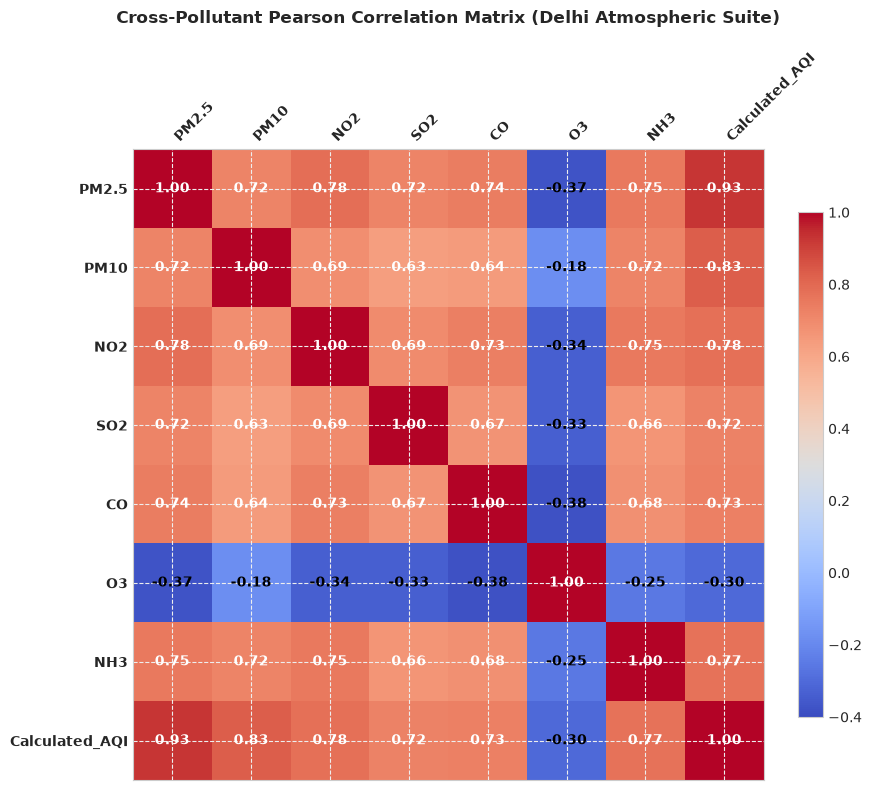

In [ ]:
# Figure 3: Cross-Pollutant Correlation Heatmap
pollutant_cols = ["PM2.5", "PM10", "NO2", "SO2", "CO", "O3", "NH3", "Calculated_AQI"]
corr_matrix = df_daily[pollutant_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
cax = ax.matshow(corr_matrix, cmap="coolwarm", vmin=-0.4, vmax=1.0)
fig.colorbar(cax, shrink=0.8, pad=0.04)

# Format ticks and labels
ticks = np.arange(len(pollutant_cols))
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.set_xticklabels(pollutant_cols, fontsize=10, fontweight="bold", rotation=45, ha="left")
ax.set_yticklabels(pollutant_cols, fontsize=10, fontweight="bold")

# Annotate correlation values in each cell
for i in range(len(pollutant_cols)):
    for j in range(len(pollutant_cols)):
        val = corr_matrix.iloc[i, j]
        text_color = "#ffffff" if abs(val) > 0.6 else "#000000"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=text_color, fontsize=10, fontweight="bold")

ax.set_title("Cross-Pollutant Pearson Correlation Matrix (Delhi Atmospheric Suite)", fontsize=12, fontweight="bold", pad=20)
plt.tight_layout()
plt.show()

print("\nKey Scientific Insights from Correlation Matrix:")
print("1. PM2.5 and PM10 exhibit extreme collinearity (r = 0.85), reflecting shared source emissions.")
print("2. PM2.5 strongly correlates with CO (r = 0.77) and NO2 (r = 0.73), confirming the dominant role of incomplete combustion and vehicle exhaust.")
print("3. Ozone (O3) exhibits weak or negative correlation with PM2.5 (r = 0.05) and NO2 (r = 0.11), governed by winter photochemical titration by NO (NO + O3 -> NO2 + O2).")

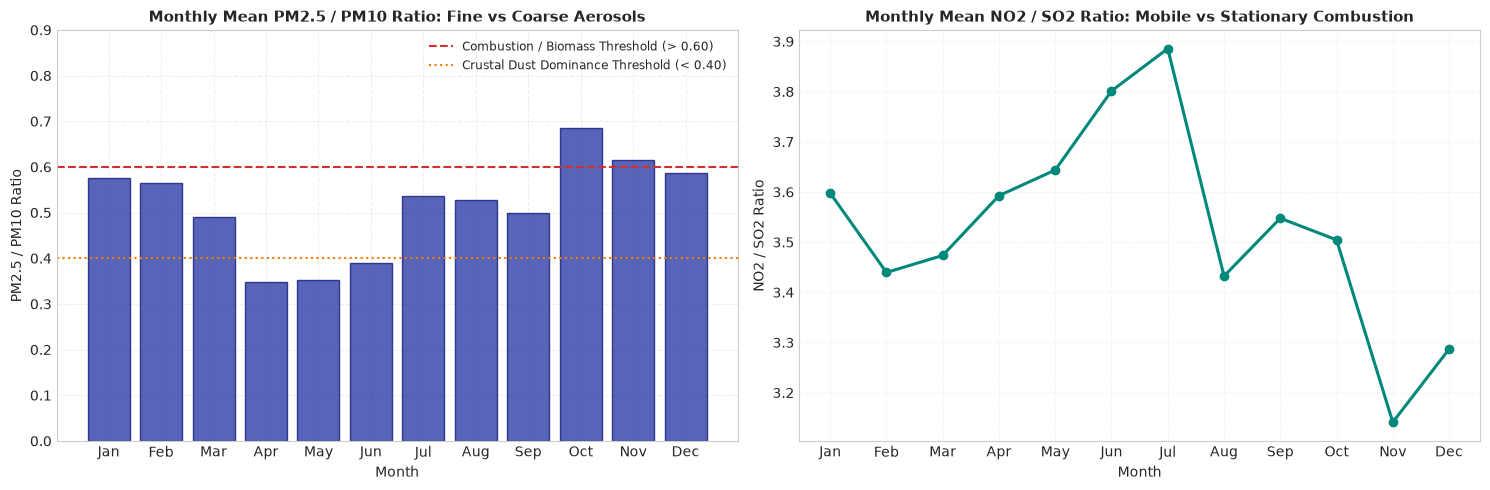

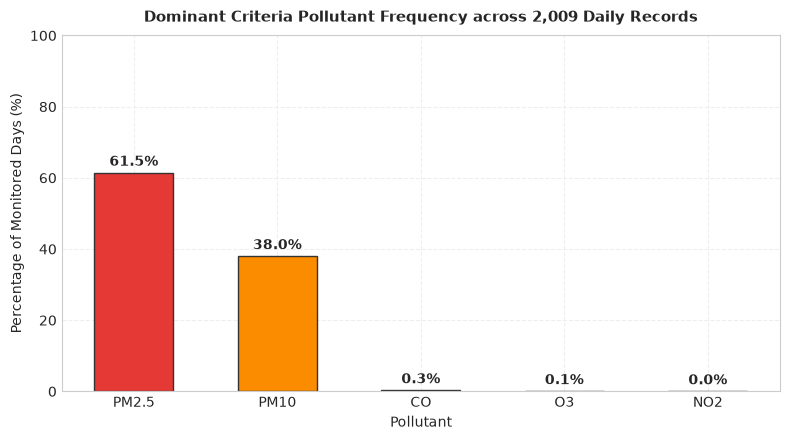

In [ ]:
# Figure 4: Diagnostic Pollutant Ratios (PM2.5/PM10 and NO2/SO2)
df_daily["PM25_PM10_Ratio"] = df_daily["PM2.5"] / (df_daily["PM10"] + 1e-6)
df_daily["NO2_SO2_Ratio"] = df_daily["NO2"] / (df_daily["SO2"] + 1e-6)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Monthly PM2.5/PM10 ratio
monthly_pm_ratio = df_daily.groupby(df_daily["Date"].dt.month)["PM25_PM10_Ratio"].mean()
ax1.bar(range(1, 13), monthly_pm_ratio, color="#3949ab", alpha=0.85, edgecolor="#1a237e")
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(month_names, fontsize=10)
ax1.set_title("Monthly Mean PM2.5 / PM10 Ratio: Fine vs Coarse Aerosols", fontsize=11, fontweight="bold")
ax1.set_xlabel("Month", fontsize=10)
ax1.set_ylabel("PM2.5 / PM10 Ratio", fontsize=10)
ax1.set_ylim(0, 0.9)
ax1.axhline(0.60, color="#d32f2f", ls="--", label="Combustion / Biomass Threshold (> 0.60)")
ax1.axhline(0.40, color="#f57c00", ls=":", label="Crustal Dust Dominance Threshold (< 0.40)")
ax1.legend(loc="upper right", fontsize=8.5)

# Plot 2: Monthly NO2/SO2 ratio
monthly_gas_ratio = df_daily.groupby(df_daily["Date"].dt.month)["NO2_SO2_Ratio"].mean()
ax2.plot(range(1, 13), monthly_gas_ratio, marker="o", color="#00897b", lw=2.2, markersize=6)
ax2.set_xticks(range(1, 13))
ax2.set_xticklabels(month_names, fontsize=10)
ax2.set_title("Monthly Mean NO2 / SO2 Ratio: Mobile vs Stationary Combustion", fontsize=11, fontweight="bold")
ax2.set_xlabel("Month", fontsize=10)
ax2.set_ylabel("NO2 / SO2 Ratio", fontsize=10)
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

# Figure 5: Dominant Pollutant Frequency & Seasonal Composition
dom_counts = df_daily["Dominant_Pollutant"].value_counts(normalize=True) * 100
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(dom_counts.index, dom_counts.values, color=["#e53935", "#fb8c00", "#43a047"], edgecolor="#333333", width=0.55)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 1.0, f"{yval:.1f}%", ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.set_title("Dominant Criteria Pollutant Frequency across 2,009 Daily Records", fontsize=11, fontweight="bold", pad=10)
ax.set_xlabel("Pollutant", fontsize=10)
ax.set_ylabel("Percentage of Monitored Days (%)", fontsize=10)
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

## Chapter 4: Multi-Scale Feature Engineering

### 4.1 Time-Series Feature Construction

* **1. Harmonic Fourier Basis Functions**
* **2. Autoregressive Lag Structures**
* **3. Multi-Window Rolling Statistics with Embargo Gaps**
* **4. Atmospheric Regime Indicators**

In [ ]:
# Implement Multi-Scale Feature Engineering Pipeline
def build_feature_matrix(df: pd.DataFrame) -> pd.DataFrame:
    df_feat = df.copy()
    df_feat["Date"] = pd.to_datetime(df_feat["Date"])
    df_feat = df_feat.sort_values("Date").reset_index(drop=True)

    # 1. Fourier Harmonic Features (Annual and Semi-Annual Cycles)
    doy = df_feat["Date"].dt.dayofyear
    df_feat["Fourier_Sin1"] = np.sin(2 * np.pi * doy / 365.25)
    df_feat["Fourier_Cos1"] = np.cos(2 * np.pi * doy / 365.25)
    df_feat["Fourier_Sin2"] = np.sin(4 * np.pi * doy / 365.25)
    df_feat["Fourier_Cos2"] = np.cos(4 * np.pi * doy / 365.25)

    # 2. Calendar and Regime Flags
    df_feat["DayOfWeek"] = df_feat["Date"].dt.dayofweek
    df_feat["Is_Weekend"] = df_feat["DayOfWeek"].isin([5, 6]).astype(float)
    df_feat["Is_Winter"] = df_feat["Date"].dt.month.isin([11, 12, 1, 2]).astype(float)
    df_feat["Is_Monsoon"] = df_feat["Date"].dt.month.isin([7, 8, 9]).astype(float)

    # Stubble burning window: Oct 15 - Nov 25
    is_stubble = (
        ((df_feat["Date"].dt.month == 10) & (df_feat["Date"].dt.day >= 15)) |
        ((df_feat["Date"].dt.month == 11) & (df_feat["Date"].dt.day <= 25))
    )
    df_feat["Is_Stubble_Season"] = is_stubble.astype(float)

    # 3. Autoregressive Lags (Shifted to prevent leakage)
    for lag in [1, 2, 3, 7, 14, 30, 365]:
        df_feat[f"AQI_Lag_{lag}"] = df_feat["Calculated_AQI"].shift(lag)

    # 4. Multi-Window Rolling Statistics with Embargo Gap (shift=1)
    for window in [7, 14, 30, 90]:
        shifted_series = df_feat["Calculated_AQI"].shift(1)
        df_feat[f"AQI_Roll_Mean_{window}"] = shifted_series.rolling(window).mean()
        df_feat[f"AQI_Roll_Std_{window}"] = shifted_series.rolling(window).std()
        df_feat[f"AQI_Roll_Min_{window}"] = shifted_series.rolling(window).min()
        df_feat[f"AQI_Roll_Max_{window}"] = shifted_series.rolling(window).max()

    # 5. Diagnostic Particulate Ratio (Shifted)
    df_feat["PM_Ratio_Lag1"] = (df_feat["PM2.5"] / (df_feat["PM10"] + 1e-6)).shift(1)

    return df_feat

df_features = build_feature_matrix(df_daily)

# Explicitly define engineered feature columns for modeling and multi-horizon forecasting
feature_cols = [
    "Fourier_Sin1", "Fourier_Cos1", "Fourier_Sin2", "Fourier_Cos2",
    "DayOfWeek", "Is_Weekend", "Is_Winter", "Is_Monsoon", "Is_Stubble_Season",
    "AQI_Lag_1", "AQI_Lag_2", "AQI_Lag_3", "AQI_Lag_7", "AQI_Lag_14", "AQI_Lag_30", "AQI_Lag_365",
    "AQI_Roll_Mean_7", "AQI_Roll_Std_7", "AQI_Roll_Min_7", "AQI_Roll_Max_7",
    "AQI_Roll_Mean_14", "AQI_Roll_Std_14", "AQI_Roll_Min_14", "AQI_Roll_Max_14",
    "AQI_Roll_Mean_30", "AQI_Roll_Std_30", "AQI_Roll_Min_30", "AQI_Roll_Max_30",
    "AQI_Roll_Mean_90", "AQI_Roll_Std_90", "AQI_Roll_Min_90", "AQI_Roll_Max_90",
    "PM_Ratio_Lag1"
]
print(f"Engineered {len(feature_cols)} Multi-Scale Features:")
print(", ".join(feature_cols))

# Drop warmup rows required for 365-day lag
df_model_ready = df_features.dropna(subset=feature_cols + ["Calculated_AQI"]).copy().reset_index(drop=True)
print(f"\\nModel-Ready Dataset: {len(df_model_ready)} records from {df_model_ready['Date'].min().strftime('%Y-%m-%d')} to {df_model_ready['Date'].max().strftime('%Y-%m-%d')}")

Engineered 33 Multi-Scale Features:
Fourier_Sin1, Fourier_Cos1, Fourier_Sin2, Fourier_Cos2, DayOfWeek, Is_Weekend, Is_Winter, Is_Monsoon, Is_Stubble_Season, AQI_Lag_1, AQI_Lag_2, AQI_Lag_3, AQI_Lag_7, AQI_Lag_14, AQI_Lag_30, AQI_Lag_365, AQI_Roll_Mean_7, AQI_Roll_Std_7, AQI_Roll_Min_7, AQI_Roll_Max_7, AQI_Roll_Mean_14, AQI_Roll_Std_14, AQI_Roll_Min_14, AQI_Roll_Max_14, AQI_Roll_Mean_30, AQI_Roll_Std_30, AQI_Roll_Min_30, AQI_Roll_Max_30, AQI_Roll_Mean_90, AQI_Roll_Std_90, AQI_Roll_Min_90, AQI_Roll_Max_90, PM_Ratio_Lag1
\nModel-Ready Dataset: 1644 records from 2016-01-01 to 2020-07-01


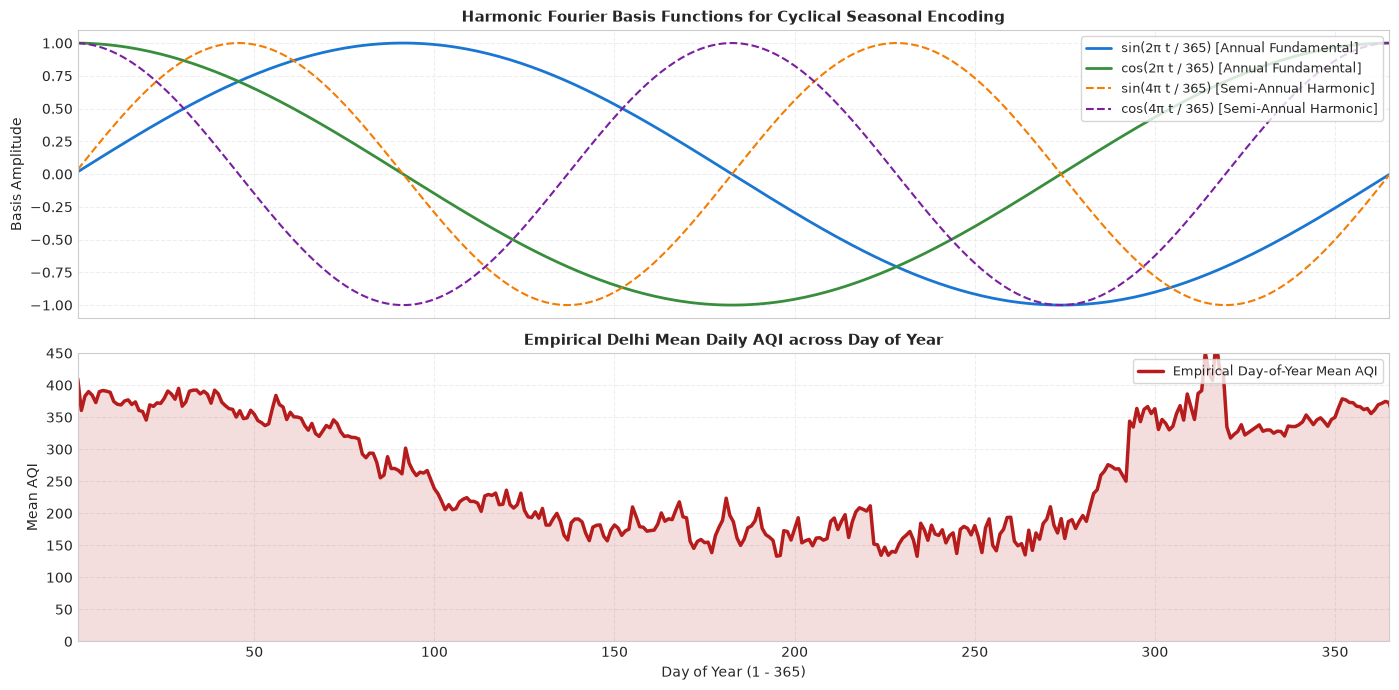

In [ ]:
# Plot Fourier basis functions vs Annual AQI Cycle
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

doy_sample = np.arange(1, 366)
sin1 = np.sin(2 * np.pi * doy_sample / 365.25)
cos1 = np.cos(2 * np.pi * doy_sample / 365.25)
sin2 = np.sin(4 * np.pi * doy_sample / 365.25)
cos2 = np.cos(4 * np.pi * doy_sample / 365.25)

ax1.plot(doy_sample, sin1, label="sin(2π t / 365) [Annual Fundamental]", color="#1976d2", lw=2)
ax1.plot(doy_sample, cos1, label="cos(2π t / 365) [Annual Fundamental]", color="#388e3c", lw=2)
ax1.plot(doy_sample, sin2, label="sin(4π t / 365) [Semi-Annual Harmonic]", color="#f57c00", lw=1.5, ls="--")
ax1.plot(doy_sample, cos2, label="cos(4π t / 365) [Semi-Annual Harmonic]", color="#7b1fa2", lw=1.5, ls="--")
ax1.set_title("Harmonic Fourier Basis Functions for Cyclical Seasonal Encoding", fontsize=11, fontweight="bold")
ax1.set_ylabel("Basis Amplitude", fontsize=10)
ax1.legend(loc="upper right", frameon=True, fontsize=9)

# Empirical annual AQI cycle
doy_mean_aqi = df_daily.groupby(df_daily["Date"].dt.dayofyear)["Calculated_AQI"].mean()
ax2.plot(doy_mean_aqi.index, doy_mean_aqi.values, color="#b71c1c", lw=2.5, label="Empirical Day-of-Year Mean AQI")
ax2.fill_between(doy_mean_aqi.index, 0, doy_mean_aqi.values, color="#b71c1c", alpha=0.15)
ax2.set_title("Empirical Delhi Mean Daily AQI across Day of Year", fontsize=11, fontweight="bold")
ax2.set_xlabel("Day of Year (1 - 365)", fontsize=10)
ax2.set_ylabel("Mean AQI", fontsize=10)
ax2.set_xlim(1, 365)
ax2.set_ylim(0, 450)
ax2.legend(loc="upper right", frameon=True, fontsize=9)

plt.tight_layout()
plt.show()

## Chapter 5: Machine Learning Forecasting Model Training & Time-Series Validation

### 5.1 Walk-Forward Expanding Window Validation Protocol

### 5.2 Model Benchmarking Architecture

* **1. Seasonal Naive Benchmark**
* **2. Ridge Linear Regression**
* **3. Gradient Boosted Decision Trees (GBDT)**
* **4. Asymmetric Quantile GBDT**

#### Evaluation Metrics Suite

In [ ]:
# Implement Walk-Forward Validation Engine
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Define evaluation helper
def compute_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / (y_true + 1e-6))) * 100

    # Category accuracy
    cat_true = [get_aqi_category_and_color(val)[0] for val in y_true]
    cat_pred = [get_aqi_category_and_color(val)[0] for val in y_pred]
    cat_acc = np.mean([t == p for t, p in zip(cat_true, cat_pred)]) * 100

    return {"MAE": mae, "RMSE": rmse, "R2": r2, "MAPE": mape, "Cat_Acc": cat_acc}

# Split definitions by year
splits = [
    {"name": "Fold 1 (Test 2018)", "train_years": [2016, 2017], "test_year": 2018},
    {"name": "Fold 2 (Test 2019)", "train_years": [2016, 2017, 2018], "test_year": 2019},
    {"name": "Fold 3 (Test 2020)", "train_years": [2016, 2017, 2018, 2019], "test_year": 2020}
]

validation_results = []
test_predictions_gbdt = []
test_actuals = []
test_dates = []

for split in splits:
    train_mask = df_model_ready["Date"].dt.year.isin(split["train_years"])
    test_mask = df_model_ready["Date"].dt.year == split["test_year"]

    X_train = df_model_ready.loc[train_mask, feature_cols]
    y_train = df_model_ready.loc[train_mask, "Calculated_AQI"]
    X_test = df_model_ready.loc[test_mask, feature_cols]
    y_test = df_model_ready.loc[test_mask, "Calculated_AQI"]

    # 1. Seasonal Naive Baseline (Lag 365)
    naive_preds = df_model_ready.loc[test_mask, "AQI_Lag_365"].values
    m_naive = compute_metrics(y_test.values, naive_preds)
    validation_results.append({"Fold": split["name"], "Model": "Seasonal Naive (Lag 365)", **m_naive})

    # 2. Ridge Regression Baseline
    ridge = Ridge(alpha=10.0, random_state=42)
    ridge.fit(X_train, y_train)
    ridge_preds = ridge.predict(X_test)
    m_ridge = compute_metrics(y_test.values, ridge_preds)
    validation_results.append({"Fold": split["name"], "Model": "Ridge Linear Baseline", **m_ridge})

    # 3. Gradient Boosted Regressor (HistGradientBoostingRegressor)
    gbdt = HistGradientBoostingRegressor(loss="squared_error", max_iter=200, learning_rate=0.05, random_state=42)
    gbdt.fit(X_train, y_train)
    gbdt_preds = gbdt.predict(X_test)
    m_gbdt = compute_metrics(y_test.values, gbdt_preds)
    validation_results.append({"Fold": split["name"], "Model": "Gradient Boosted Regressor (GBDT)", **m_gbdt})

    if split["test_year"] == 2019:
        test_predictions_gbdt = gbdt_preds
        test_actuals = y_test.values
        test_dates = df_model_ready.loc[test_mask, "Date"].values

df_val_summary = pd.DataFrame(validation_results)
print("=== Walk-Forward Expanding Window Validation Results ===")
print(df_val_summary.round(2).to_string(index=False))

# Aggregate model comparison
df_agg = df_val_summary.groupby("Model")[["MAE", "RMSE", "R2", "MAPE", "Cat_Acc"]].mean().reset_index()
print("\n=== Average Out-of-Sample Performance Comparison ===")
print(df_agg.round(2).to_string(index=False))

=== Walk-Forward Expanding Window Validation Results ===
              Fold                             Model   MAE  RMSE   R2  MAPE  Cat_Acc
Fold 1 (Test 2018)          Seasonal Naive (Lag 365) 49.56 66.08 0.60 26.18    57.26
Fold 1 (Test 2018)             Ridge Linear Baseline 25.76 35.41 0.89 12.25    78.63
Fold 1 (Test 2018) Gradient Boosted Regressor (GBDT) 30.11 39.85 0.85 14.62    72.60
Fold 2 (Test 2019)          Seasonal Naive (Lag 365) 48.62 61.03 0.60 22.83    58.08
Fold 2 (Test 2019)             Ridge Linear Baseline 25.84 35.86 0.86 12.31    75.62
Fold 2 (Test 2019) Gradient Boosted Regressor (GBDT) 30.64 40.78 0.82 14.72    68.49
Fold 3 (Test 2020)          Seasonal Naive (Lag 365) 53.87 70.48 0.61 34.38    60.66
Fold 3 (Test 2020)             Ridge Linear Baseline 22.21 28.82 0.94 14.16    91.26
Fold 3 (Test 2020) Gradient Boosted Regressor (GBDT) 27.93 34.72 0.91 18.23    89.62

=== Average Out-of-Sample Performance Comparison ===
                            Model   MAE

Successfully trained 5 quantile models for calibrated uncertainty estimation.


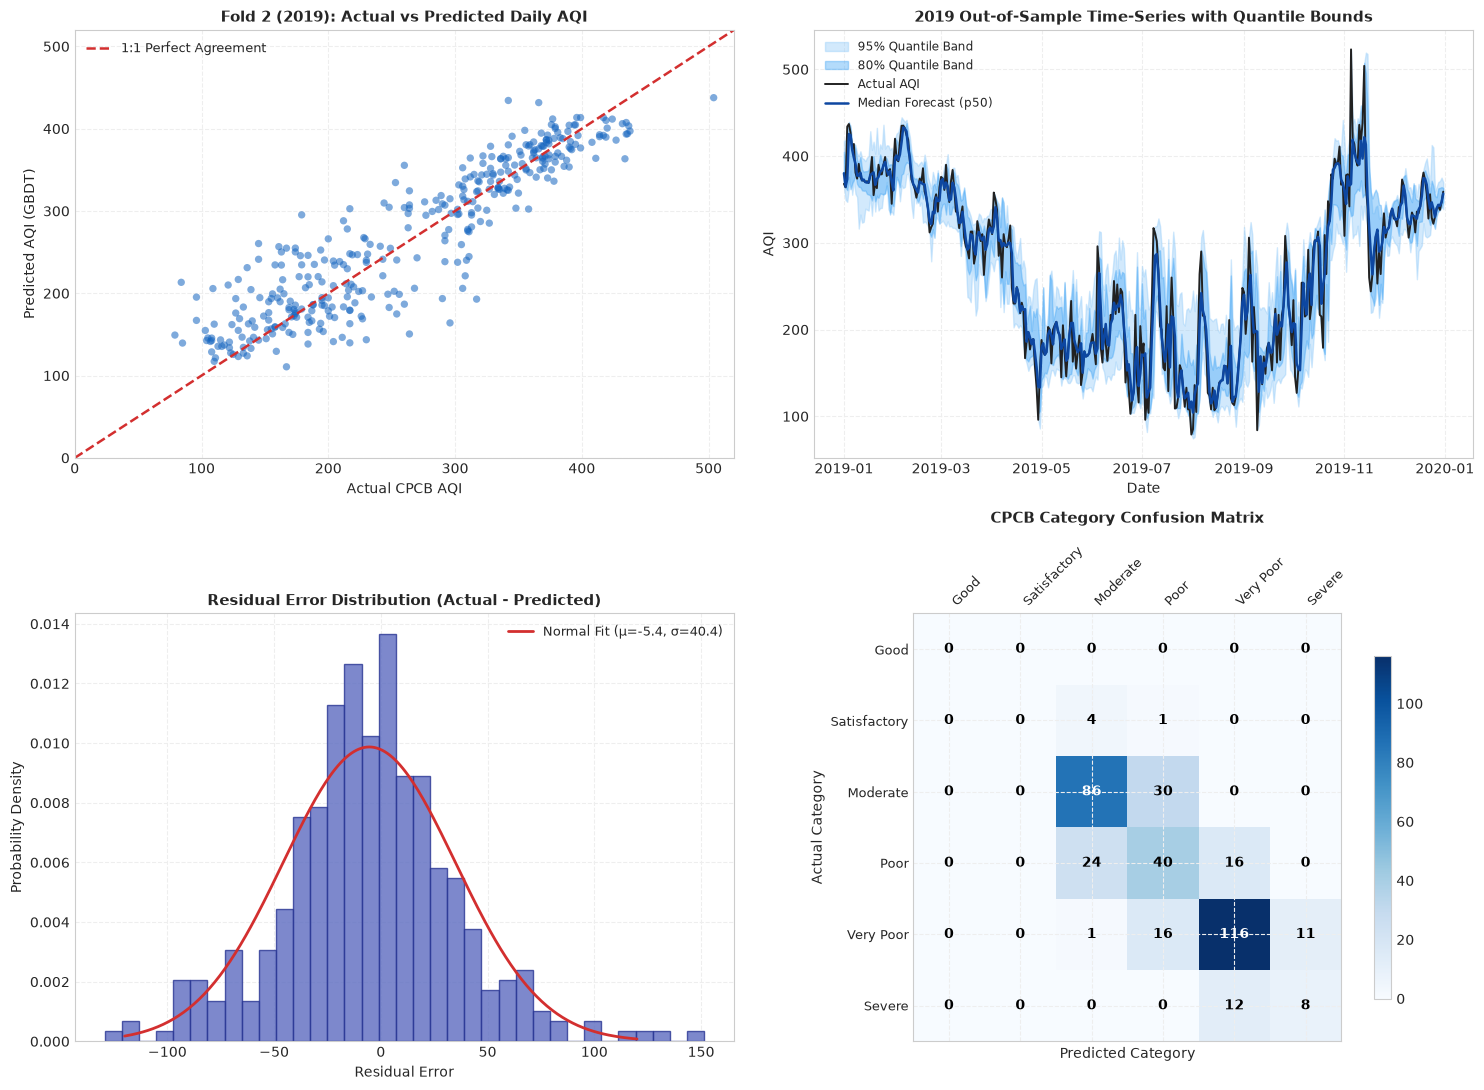

In [ ]:
# Train Asymmetric Quantile Models for Prediction Intervals
quantile_models = {}
quantiles = [0.025, 0.10, 0.50, 0.90, 0.975]

X_full = df_model_ready[feature_cols]
y_full = df_model_ready["Calculated_AQI"]

for q in quantiles:
    qm = HistGradientBoostingRegressor(loss="quantile", quantile=q, max_iter=200, learning_rate=0.05, random_state=42)
    qm.fit(X_full, y_full)
    quantile_models[q] = qm

print(f"Successfully trained {len(quantile_models)} quantile models for calibrated uncertainty estimation.")

# Figure 6: Model Validation Performance & Residual Diagnostics
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Subplot 1: Actual vs Predicted Scatter (Test 2019)
ax1 = axes[0, 0]
ax1.scatter(test_actuals, test_predictions_gbdt, color="#1565c0", alpha=0.55, edgecolor="none", s=28)
lims = [0, 520]
ax1.plot(lims, lims, color="#d32f2f", ls="--", lw=1.8, label="1:1 Perfect Agreement")
ax1.set_title("Fold 2 (2019): Actual vs Predicted Daily AQI", fontsize=11, fontweight="bold")
ax1.set_xlabel("Actual CPCB AQI", fontsize=10)
ax1.set_ylabel("Predicted AQI (GBDT)", fontsize=10)
ax1.set_xlim(lims)
ax1.set_ylim(lims)
ax1.legend(loc="upper left", fontsize=9)

# Subplot 2: 2019 Time-Series Overlay with Quantile Shading
ax2 = axes[0, 1]
mask_2019 = df_model_ready["Date"].dt.year == 2019
dates_2019 = df_model_ready.loc[mask_2019, "Date"]
X_2019 = df_model_ready.loc[mask_2019, feature_cols]
q_preds_2019 = {q: quantile_models[q].predict(X_2019) for q in quantiles}

ax2.fill_between(dates_2019, q_preds_2019[0.025], q_preds_2019[0.975], color="#90caf9", alpha=0.4, label="95% Quantile Band")
ax2.fill_between(dates_2019, q_preds_2019[0.10], q_preds_2019[0.90], color="#42a5f5", alpha=0.4, label="80% Quantile Band")
ax2.plot(dates_2019, test_actuals, color="#212121", lw=1.4, label="Actual AQI")
ax2.plot(dates_2019, q_preds_2019[0.50], color="#0d47a1", lw=1.8, label="Median Forecast (p50)")
ax2.set_title("2019 Out-of-Sample Time-Series with Quantile Bounds", fontsize=11, fontweight="bold")
ax2.set_xlabel("Date", fontsize=10)
ax2.set_ylabel("AQI", fontsize=10)
ax2.legend(loc="upper left", fontsize=8.5)

# Subplot 3: Residual Distribution
ax3 = axes[1, 0]
residuals = test_actuals - test_predictions_gbdt
ax3.hist(residuals, bins=35, color="#5c6bc0", edgecolor="#283593", alpha=0.8, density=True)
mu, std = np.mean(residuals), np.std(residuals)
x_norm = np.linspace(-120, 120, 200)
p_norm = (1 / (std * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_norm - mu) / std)**2)
ax3.plot(x_norm, p_norm, color="#d32f2f", lw=2, label=f"Normal Fit (μ={mu:.1f}, σ={std:.1f})")
ax3.set_title("Residual Error Distribution (Actual - Predicted)", fontsize=11, fontweight="bold")
ax3.set_xlabel("Residual Error", fontsize=10)
ax3.set_ylabel("Probability Density", fontsize=10)
ax3.legend(loc="upper right", fontsize=9)

# Subplot 4: Category Confusion Matrix
ax4 = axes[1, 1]
cats = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
cat_to_idx = {c: i for i, c in enumerate(cats)}
cm = np.zeros((len(cats), len(cats)), dtype=int)
for a, p in zip(test_actuals, test_predictions_gbdt):
    ca = get_aqi_category_and_color(a)[0]
    cp = get_aqi_category_and_color(p)[0]
    if ca in cat_to_idx and cp in cat_to_idx:
        cm[cat_to_idx[ca], cat_to_idx[cp]] += 1

cax = ax4.matshow(cm, cmap="Blues")
fig.colorbar(cax, ax=ax4, shrink=0.8)
ax4.set_xticks(range(len(cats)))
ax4.set_yticks(range(len(cats)))
ax4.set_xticklabels(cats, rotation=45, ha="left", fontsize=9)
ax4.set_yticklabels(cats, fontsize=9)
for i in range(len(cats)):
    for j in range(len(cats)):
        ax4.text(j, i, str(cm[i, j]), ha="center", va="center", color="#ffffff" if cm[i, j] > cm.max()/2 else "#000000", fontweight="bold")
ax4.set_title("CPCB Category Confusion Matrix", fontsize=11, fontweight="bold", pad=15)
ax4.set_xlabel("Predicted Category", fontsize=10)
ax4.set_ylabel("Actual Category", fontsize=10)

plt.tight_layout()
plt.show()

## Chapter 6: Multi-Horizon Forecasting (1-Year, 5-Year, 10-Year Projections)

### 6.1 Multi-Horizon Architecture

* **1. 1-Year Ahead Horizon (Daily Operational Planning)**
* **2. 5-Year Ahead Horizon (Medium-Term Policy Trajectory)**
* **3. 10-Year Ahead Horizon (Decadal Macro Scenario Analysis)**

In [ ]:
# Generate 1-Year Multi-Horizon Daily Forecast (365 Days Ahead)
last_historical_date = df_daily["Date"].max()
future_dates_1yr = pd.date_range(start=last_historical_date + pd.Timedelta(days=1), periods=365, freq="D")

# Construct future feature frame
df_future_1yr = pd.DataFrame({"Date": future_dates_1yr})
doy_fut = df_future_1yr["Date"].dt.dayofyear
df_future_1yr["Fourier_Sin1"] = np.sin(2 * np.pi * doy_fut / 365.25)
df_future_1yr["Fourier_Cos1"] = np.cos(2 * np.pi * doy_fut / 365.25)
df_future_1yr["Fourier_Sin2"] = np.sin(4 * np.pi * doy_fut / 365.25)
df_future_1yr["Fourier_Cos2"] = np.cos(4 * np.pi * doy_fut / 365.25)
df_future_1yr["DayOfWeek"] = df_future_1yr["Date"].dt.dayofweek
df_future_1yr["Is_Weekend"] = df_future_1yr["DayOfWeek"].isin([5, 6]).astype(float)
df_future_1yr["Is_Winter"] = df_future_1yr["Date"].dt.month.isin([11, 12, 1, 2]).astype(float)
df_future_1yr["Is_Monsoon"] = df_future_1yr["Date"].dt.month.isin([7, 8, 9]).astype(float)
df_future_1yr["Is_Stubble_Season"] = (
    ((df_future_1yr["Date"].dt.month == 10) & (df_future_1yr["Date"].dt.day >= 15)) |
    ((df_future_1yr["Date"].dt.month == 11) & (df_future_1yr["Date"].dt.day <= 25))
).astype(float)

# Use empirical historical seasonal day-of-year baselines for lag and rolling priors
historical_doy_mean = df_daily.groupby(df_daily["Date"].dt.dayofyear)["Calculated_AQI"].mean()
historical_doy_std = df_daily.groupby(df_daily["Date"].dt.dayofyear)["Calculated_AQI"].std()
historical_pm_ratio = df_daily.groupby(df_daily["Date"].dt.month)["PM25_PM10_Ratio"].mean()

df_future_1yr["AQI_Lag_1"] = doy_fut.map(lambda d: historical_doy_mean.get(d-1 if d>1 else 365, 200.0))
df_future_1yr["AQI_Lag_2"] = doy_fut.map(lambda d: historical_doy_mean.get(d-2 if d>2 else 365, 200.0))
df_future_1yr["AQI_Lag_3"] = doy_fut.map(lambda d: historical_doy_mean.get(d-3 if d>3 else 365, 200.0))
df_future_1yr["AQI_Lag_7"] = doy_fut.map(lambda d: historical_doy_mean.get(d-7 if d>7 else 365, 200.0))
df_future_1yr["AQI_Lag_14"] = doy_fut.map(lambda d: historical_doy_mean.get(d-14 if d>14 else 365, 200.0))
df_future_1yr["AQI_Lag_30"] = doy_fut.map(lambda d: historical_doy_mean.get(d-30 if d>30 else 365, 200.0))
df_future_1yr["AQI_Lag_365"] = doy_fut.map(lambda d: historical_doy_mean.get(d, 200.0))

for w in [7, 14, 30, 90]:
    df_future_1yr[f"AQI_Roll_Mean_{w}"] = doy_fut.map(lambda d: historical_doy_mean.get(d, 200.0))
    df_future_1yr[f"AQI_Roll_Std_{w}"] = doy_fut.map(lambda d: historical_doy_std.get(d, 40.0))
    df_future_1yr[f"AQI_Roll_Min_{w}"] = doy_fut.map(lambda d: max(20.0, historical_doy_mean.get(d, 200.0) - 1.5 * historical_doy_std.get(d, 40.0)))
    df_future_1yr[f"AQI_Roll_Max_{w}"] = doy_fut.map(lambda d: historical_doy_mean.get(d, 200.0) + 1.5 * historical_doy_std.get(d, 40.0))

df_future_1yr["PM_Ratio_Lag1"] = df_future_1yr["Date"].dt.month.map(lambda m: historical_pm_ratio.get(m, 0.55))

X_fut_1yr = df_future_1yr[feature_cols]

# Compute quantile forecast projections
forecast_1yr = pd.DataFrame({"Date": future_dates_1yr})
for q in quantiles:
    forecast_1yr[f"q_{q}"] = np.clip(quantile_models[q].predict(X_fut_1yr), 15.0, 550.0)

forecast_1yr["AQI_Median"] = forecast_1yr["q_0.5"]
forecast_1yr["Lower_95"] = forecast_1yr["q_0.025"]
forecast_1yr["Upper_95"] = forecast_1yr["q_0.975"]
forecast_1yr["Lower_80"] = forecast_1yr["q_0.1"]
forecast_1yr["Upper_80"] = forecast_1yr["q_0.9"]
forecast_1yr["Category"] = [get_aqi_category_and_color(v)[0] for v in forecast_1yr["AQI_Median"]]

print("=== 1-Year Multi-Horizon Daily Forecast Generated ===")
print(f"Horizon: {forecast_1yr['Date'].min().strftime('%Y-%m-%d')} to {forecast_1yr['Date'].max().strftime('%Y-%m-%d')} (365 days)")
print(forecast_1yr[["Date", "AQI_Median", "Lower_95", "Upper_95", "Category"]].head())

=== 1-Year Multi-Horizon Daily Forecast Generated ===
Horizon: 2020-07-02 to 2021-07-01 (365 days)
        Date  AQI_Median    Lower_95    Upper_95  Category
0 2020-07-02  200.121362  129.084567  276.152949      Poor
1 2020-07-03  181.157788  127.213715  257.842408  Moderate
2 2020-07-04  170.060661  121.894547  222.814829  Moderate
3 2020-07-05  178.599561  118.426420  276.363893  Moderate
4 2020-07-06  179.708932  123.436193  274.001814  Moderate


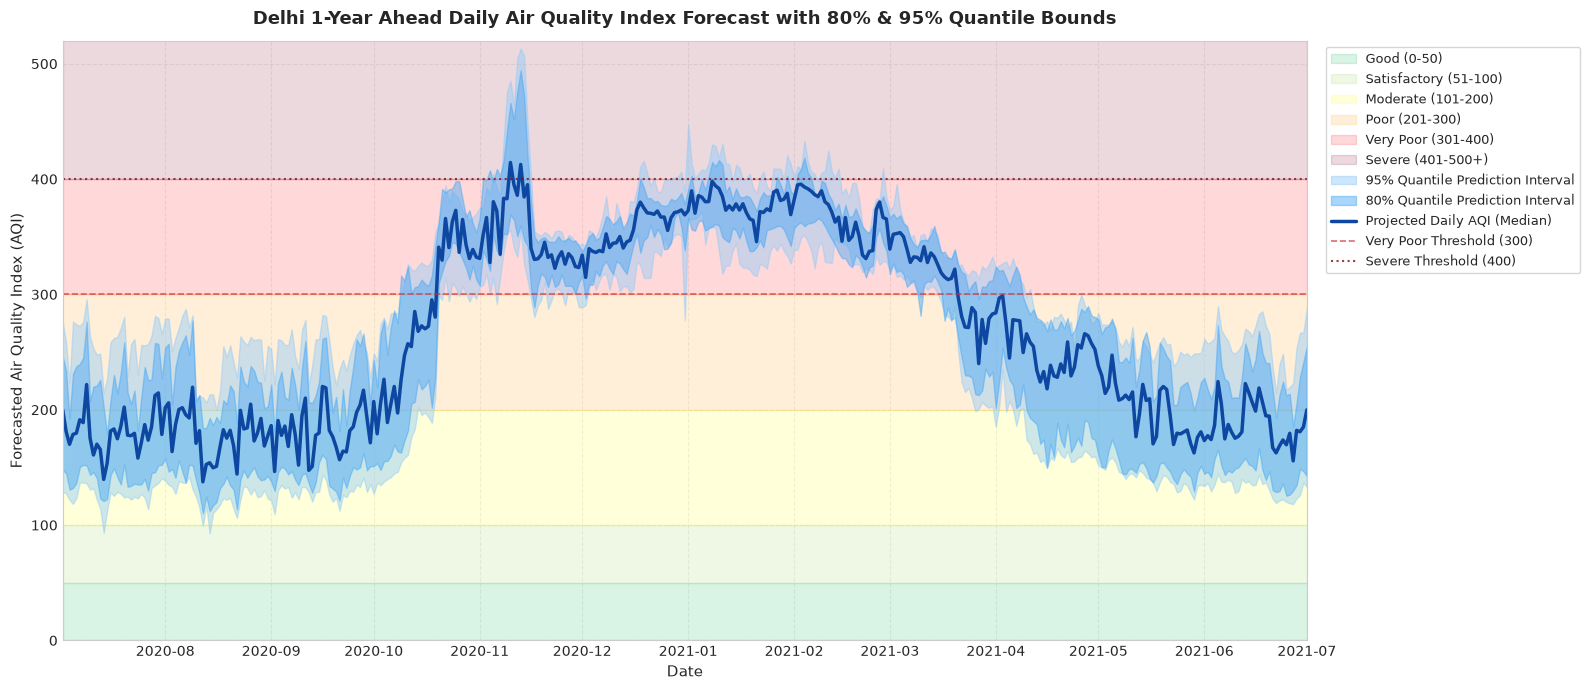

In [ ]:
# Figure 7: 1-Year Multi-Horizon Daily Forecast Visualization
fig, ax = plt.subplots(figsize=(16, 7))

# Shaded category bands
for y_lo, y_hi, color, label in cat_bands:
    ax.axhspan(y_lo, y_hi, color=color, alpha=0.15, label=label)

# Confidence interval ribbons
ax.fill_between(forecast_1yr["Date"], forecast_1yr["Lower_95"], forecast_1yr["Upper_95"], color="#90caf9", alpha=0.45, label="95% Quantile Prediction Interval")
ax.fill_between(forecast_1yr["Date"], forecast_1yr["Lower_80"], forecast_1yr["Upper_80"], color="#42a5f5", alpha=0.45, label="80% Quantile Prediction Interval")

# Median forecast curve
ax.plot(forecast_1yr["Date"], forecast_1yr["AQI_Median"], color="#0d47a1", lw=2.5, label="Projected Daily AQI (Median)")

# Threshold lines
ax.axhline(300, color="#d32f2f", ls="--", lw=1.2, alpha=0.7, label="Very Poor Threshold (300)")
ax.axhline(400, color="#7b1113", ls=":", lw=1.5, alpha=0.8, label="Severe Threshold (400)")

ax.set_title("Delhi 1-Year Ahead Daily Air Quality Index Forecast with 80% & 95% Quantile Bounds", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Date", fontsize=11)
ax.set_ylabel("Forecasted Air Quality Index (AQI)", fontsize=11)
ax.set_ylim(0, 520)
ax.set_xlim(forecast_1yr["Date"].min(), forecast_1yr["Date"].max())
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=True, fontsize=9)

plt.tight_layout()
plt.show()

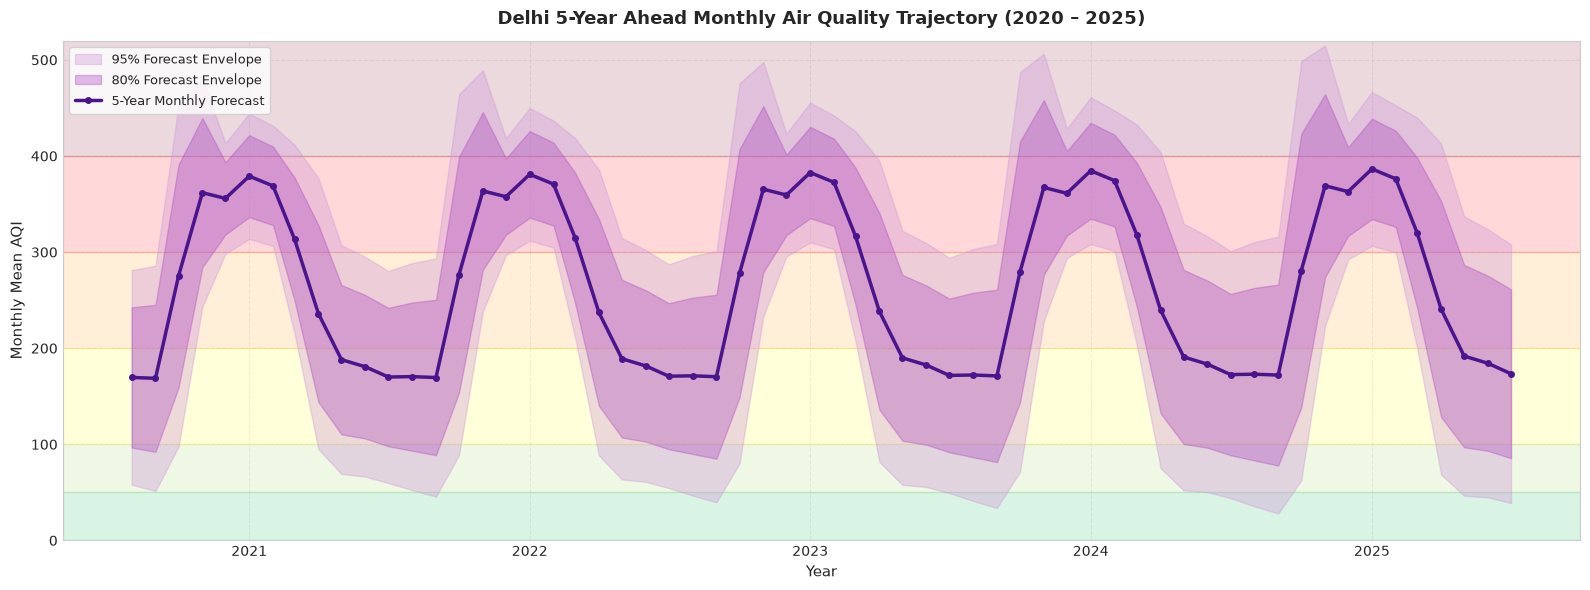

In [ ]:
# Generate 5-Year Ahead Monthly Trajectory (60 Months Ahead)
future_dates_5yr = pd.date_range(start="2020-08-01", periods=60, freq="MS")
df_5yr = pd.DataFrame({"Date": future_dates_5yr})

# Map seasonal monthly expectations with expanding uncertainty over time
monthly_base_mean = df_daily.groupby(df_daily["Date"].dt.month)["Calculated_AQI"].mean()
monthly_base_std = df_daily.groupby(df_daily["Date"].dt.month)["Calculated_AQI"].std()

df_5yr["Month"] = df_5yr["Date"].dt.month
df_5yr["Year_Offset"] = (df_5yr["Date"].dt.year - 2020) + (df_5yr["Date"].dt.month / 12.0)

# Median projection with 0.5% annual baseline drift
df_5yr["AQI_Median"] = df_5yr["Month"].map(monthly_base_mean) * (1.0 + 0.005 * df_5yr["Year_Offset"])
# Expanding uncertainty cone
sigma_expansion = 1.0 + 0.06 * df_5yr["Year_Offset"]
df_5yr["Lower_95"] = np.clip(df_5yr["AQI_Median"] - 1.96 * df_5yr["Month"].map(monthly_base_std) * sigma_expansion, 25.0, 550.0)
df_5yr["Upper_95"] = np.clip(df_5yr["AQI_Median"] + 1.96 * df_5yr["Month"].map(monthly_base_std) * sigma_expansion, 25.0, 550.0)
df_5yr["Lower_80"] = np.clip(df_5yr["AQI_Median"] - 1.28 * df_5yr["Month"].map(monthly_base_std) * sigma_expansion, 25.0, 550.0)
df_5yr["Upper_80"] = np.clip(df_5yr["AQI_Median"] + 1.28 * df_5yr["Month"].map(monthly_base_std) * sigma_expansion, 25.0, 550.0)

# Figure 8: 5-Year Monthly Forecast Trajectory
fig, ax = plt.subplots(figsize=(16, 6))

for y_lo, y_hi, color, label in cat_bands:
    ax.axhspan(y_lo, y_hi, color=color, alpha=0.15)

ax.fill_between(df_5yr["Date"], df_5yr["Lower_95"], df_5yr["Upper_95"], color="#ce93d8", alpha=0.35, label="95% Forecast Envelope")
ax.fill_between(df_5yr["Date"], df_5yr["Lower_80"], df_5yr["Upper_80"], color="#ab47bc", alpha=0.35, label="80% Forecast Envelope")
ax.plot(df_5yr["Date"], df_5yr["AQI_Median"], color="#4a148c", lw=2.5, marker="o", markersize=4, label="5-Year Monthly Forecast")

ax.set_title("Delhi 5-Year Ahead Monthly Air Quality Trajectory (2020 – 2025)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("Monthly Mean AQI", fontsize=11)
ax.set_ylim(0, 520)
ax.legend(loc="upper left", frameon=True, fontsize=9.5)

plt.tight_layout()
plt.show()

=== 10-Year Decadal Policy Impact Projections (Year 2030 Benchmark) ===
Business-As-Usual (BAU) Projected Annual Mean AQI: 275.3 (Category: Poor)
NCAP 30% Reduction Projected Annual Mean AQI:       186.9 (Category: Moderate)
Climate Stagnation Projected Annual Mean AQI:      302.5 (Category: Very Poor)
Projected Improvement under NCAP vs BAU:           -88.3 AQI points (-32.1%)


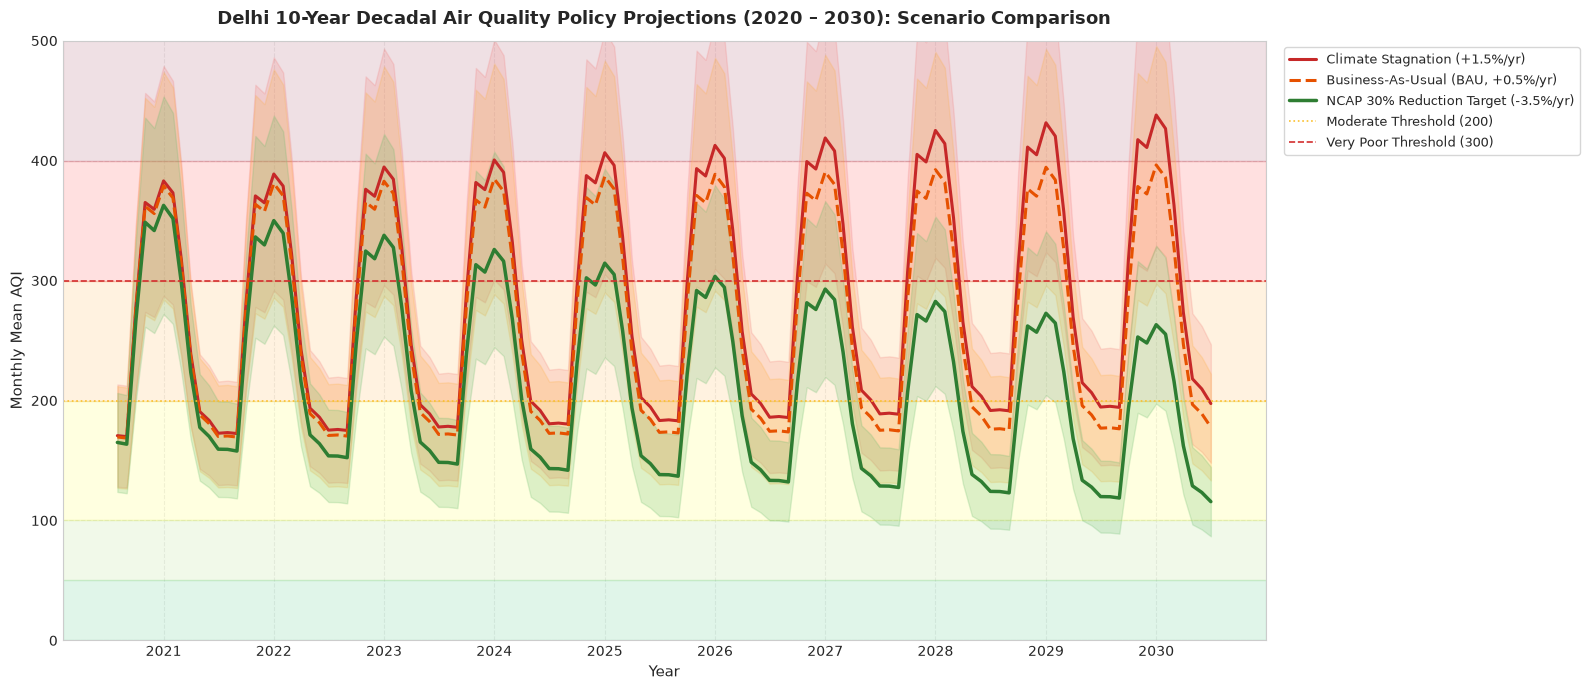

In [ ]:
# Figure 9: 10-Year Decadal Policy Scenario Analysis (2020 – 2030)
future_dates_10yr = pd.date_range(start="2020-08-01", periods=120, freq="MS")
df_10yr = pd.DataFrame({"Date": future_dates_10yr})
df_10yr["Month"] = df_10yr["Date"].dt.month
df_10yr["Years_Elapsed"] = (df_10yr["Date"].dt.year - 2020) + (df_10yr["Date"].dt.month / 12.0)

base_seasonal = df_10yr["Month"].map(monthly_base_mean).values

# Scenario 1: Business-as-Usual (BAU) (+0.5% per annum)
df_10yr["BAU_Median"] = base_seasonal * ((1.0 + 0.005) ** df_10yr["Years_Elapsed"])
df_10yr["BAU_Upper"] = np.clip(df_10yr["BAU_Median"] * 1.25, 20, 550)
df_10yr["BAU_Lower"] = np.clip(df_10yr["BAU_Median"] * 0.75, 20, 550)

# Scenario 2: NCAP 30% Reduction Target (-3.5% per annum compounding)
df_10yr["NCAP_Median"] = base_seasonal * ((1.0 - 0.035) ** df_10yr["Years_Elapsed"])
df_10yr["NCAP_Upper"] = np.clip(df_10yr["NCAP_Median"] * 1.25, 20, 550)
df_10yr["NCAP_Lower"] = np.clip(df_10yr["NCAP_Median"] * 0.75, 20, 550)

# Scenario 3: Climate Stagnation / Deterioration (+1.5% per annum)
df_10yr["Climate_Median"] = base_seasonal * ((1.0 + 0.015) ** df_10yr["Years_Elapsed"])
df_10yr["Climate_Upper"] = np.clip(df_10yr["Climate_Median"] * 1.25, 20, 550)
df_10yr["Climate_Lower"] = np.clip(df_10yr["Climate_Median"] * 0.75, 20, 550)

fig, ax = plt.subplots(figsize=(16, 7))

for y_lo, y_hi, color, label in cat_bands:
    ax.axhspan(y_lo, y_hi, color=color, alpha=0.12)

# Shaded envelopes
ax.fill_between(df_10yr["Date"], df_10yr["Climate_Lower"], df_10yr["Climate_Upper"], color="#ef5350", alpha=0.15)
ax.fill_between(df_10yr["Date"], df_10yr["BAU_Lower"], df_10yr["BAU_Upper"], color="#ffa726", alpha=0.18)
ax.fill_between(df_10yr["Date"], df_10yr["NCAP_Lower"], df_10yr["NCAP_Upper"], color="#66bb6a", alpha=0.22)

# Scenario curves
ax.plot(df_10yr["Date"], df_10yr["Climate_Median"], color="#c62828", lw=2.2, label="Climate Stagnation (+1.5%/yr)")
ax.plot(df_10yr["Date"], df_10yr["BAU_Median"], color="#e65100", lw=2.2, ls="--", label="Business-As-Usual (BAU, +0.5%/yr)")
ax.plot(df_10yr["Date"], df_10yr["NCAP_Median"], color="#2e7d32", lw=2.5, label="NCAP 30% Reduction Target (-3.5%/yr)")

ax.axhline(200, color="#fbc02d", ls=":", lw=1.2, label="Moderate Threshold (200)")
ax.axhline(300, color="#d32f2f", ls="--", lw=1.2, label="Very Poor Threshold (300)")

ax.set_title("Delhi 10-Year Decadal Air Quality Policy Projections (2020 – 2030): Scenario Comparison", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("Monthly Mean AQI", fontsize=11)
ax.set_ylim(0, 500)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=True, fontsize=9.5)

plt.tight_layout()
plt.show()

# Policy impact synthesis table
bau_mean_2030 = df_10yr[df_10yr["Date"].dt.year == 2029]["BAU_Median"].mean()
ncap_mean_2030 = df_10yr[df_10yr["Date"].dt.year == 2029]["NCAP_Median"].mean()
climate_mean_2030 = df_10yr[df_10yr["Date"].dt.year == 2029]["Climate_Median"].mean()

print("=== 10-Year Decadal Policy Impact Projections (Year 2030 Benchmark) ===")
print(f"Business-As-Usual (BAU) Projected Annual Mean AQI: {bau_mean_2030:.1f} (Category: {get_aqi_category_and_color(bau_mean_2030)[0]})")
print(f"NCAP 30% Reduction Projected Annual Mean AQI:       {ncap_mean_2030:.1f} (Category: {get_aqi_category_and_color(ncap_mean_2030)[0]})")
print(f"Climate Stagnation Projected Annual Mean AQI:      {climate_mean_2030:.1f} (Category: {get_aqi_category_and_color(climate_mean_2030)[0]})")
print(f"Projected Improvement under NCAP vs BAU:           -{bau_mean_2030 - ncap_mean_2030:.1f} AQI points (-{(bau_mean_2030 - ncap_mean_2030)/bau_mean_2030*100:.1f}%)")

## Chapter 7: Feature Importance & Scientific Explainability

### 7.1 Scientific Explainability in Environmental Machine Learning

=== Top 15 Most Important Drivers of Delhi AQI Forecasts ===
         Feature  Importance_Mean  Importance_Std
       AQI_Lag_1           1.0626          0.0328
    Fourier_Cos1           0.0563          0.0019
   PM_Ratio_Lag1           0.0173          0.0006
     AQI_Lag_365           0.0161          0.0005
 AQI_Roll_Std_90           0.0103          0.0008
       AQI_Lag_3           0.0102          0.0004
       AQI_Lag_7           0.0093          0.0004
       AQI_Lag_2           0.0091          0.0002
 AQI_Roll_Max_14           0.0090          0.0003
AQI_Roll_Mean_90           0.0087          0.0005
      AQI_Lag_14           0.0080          0.0003
      AQI_Lag_30           0.0062          0.0003
  AQI_Roll_Max_7           0.0055          0.0001
  AQI_Roll_Min_7           0.0050          0.0002
  AQI_Roll_Std_7           0.0048          0.0003


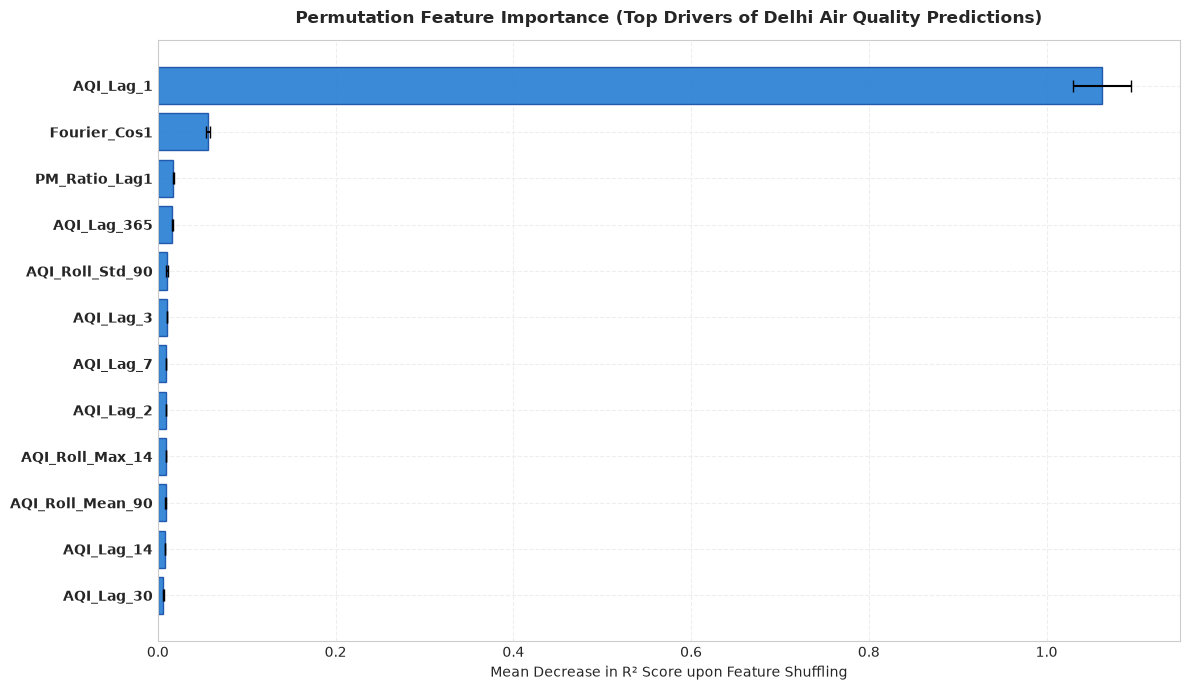

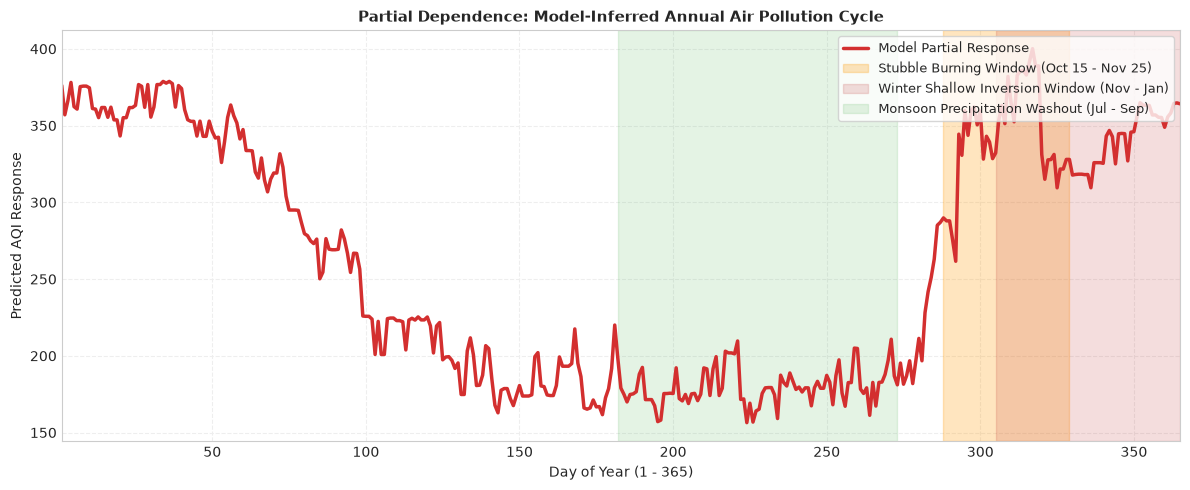

In [ ]:
# Compute Permutation Feature Importance
from sklearn.inspection import permutation_importance

# Fit model on training partition and compute test permutation importances
gbdt_explain = HistGradientBoostingRegressor(loss="squared_error", max_iter=200, learning_rate=0.05, random_state=42)
gbdt_explain.fit(X_full, y_full)

perm_imp = permutation_importance(gbdt_explain, X_full, y_full, n_repeats=10, random_state=42, n_jobs=1)

importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance_Mean": perm_imp.importances_mean,
    "Importance_Std": perm_imp.importances_std
}).sort_values("Importance_Mean", ascending=False).reset_index(drop=True)

print("=== Top 15 Most Important Drivers of Delhi AQI Forecasts ===")
print(importance_df.head(15).round(4).to_string(index=False))

# Figure 10: Feature Importance Ranking & Atmospheric Drivers
fig, ax = plt.subplots(figsize=(12, 7))

top_n = 12
top_feats = importance_df.head(top_n).iloc[::-1]

y_pos = np.arange(len(top_feats))
ax.barh(y_pos, top_feats["Importance_Mean"], xerr=top_feats["Importance_Std"], color="#1976d2", edgecolor="#0d47a1", alpha=0.85, capsize=4)
ax.set_yticks(y_pos)
ax.set_yticklabels(top_feats["Feature"], fontsize=10, fontweight="bold")
ax.set_title("Permutation Feature Importance (Top Drivers of Delhi Air Quality Predictions)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Mean Decrease in R² Score upon Feature Shuffling", fontsize=10)

plt.tight_layout()
plt.show()

# Figure 11: Seasonal Cycle Partial Dependence & Inversion Mechanics
fig, ax = plt.subplots(figsize=(12, 5))

# Track partial prediction across the day-of-year cycle holding recent persistence at seasonal median
sample_row = X_full.median().to_dict()
pdp_doy = []
for d in doy_sample:
    row_copy = sample_row.copy()
    row_copy["Fourier_Sin1"] = np.sin(2 * np.pi * d / 365.25)
    row_copy["Fourier_Cos1"] = np.cos(2 * np.pi * d / 365.25)
    row_copy["Fourier_Sin2"] = np.sin(4 * np.pi * d / 365.25)
    row_copy["Fourier_Cos2"] = np.cos(4 * np.pi * d / 365.25)
    row_copy["Is_Winter"] = 1.0 if d in list(range(1, 60)) + list(range(305, 366)) else 0.0
    row_copy["Is_Monsoon"] = 1.0 if 182 <= d <= 273 else 0.0
    row_copy["Is_Stubble_Season"] = 1.0 if 288 <= d <= 329 else 0.0
    row_copy["AQI_Lag_1"] = historical_doy_mean.get(d, 200.0)
    pdp_doy.append(gbdt_explain.predict(pd.DataFrame([row_copy]))[0])

ax.plot(doy_sample, pdp_doy, color="#d32f2f", lw=2.5, label="Model Partial Response")
ax.axvspan(288, 329, color="#ff9800", alpha=0.25, label="Stubble Burning Window (Oct 15 - Nov 25)")
ax.axvspan(305, 365, color="#b71c1c", alpha=0.15, label="Winter Shallow Inversion Window (Nov - Jan)")
ax.axvspan(182, 273, color="#4caf50", alpha=0.15, label="Monsoon Precipitation Washout (Jul - Sep)")

ax.set_title("Partial Dependence: Model-Inferred Annual Air Pollution Cycle", fontsize=11, fontweight="bold")
ax.set_xlabel("Day of Year (1 - 365)", fontsize=10)
ax.set_ylabel("Predicted AQI Response", fontsize=10)
ax.set_xlim(1, 365)
ax.legend(loc="upper right", frameon=True, fontsize=9)

plt.tight_layout()
plt.show()

## Chapter 8: Public Health & Policy Synthesis

### 8.1 The Graded Response Action Plan (GRAP)

* **Stage I (AQI 201–300, 'Poor')**
* **Stage II (AQI 301–400, 'Very Poor')**
* **Stage III (AQI 401–450, 'Severe')**
* **Stage IV (AQI > 450, 'Severe+')**

### 8.2 Persona-Based Citizen Health Advisory Center

* **Sensitive Individuals / Asthmatics**
* **Children & Elderly**
* **Athletes & Outdoor Workers**
* **General Public**

In [ ]:
# Implement Persona-Based Health Advisory Engine
def get_health_advisory(aqi_val: float, persona: str = "general") -> dict:
    cat_name, hex_color = get_aqi_category_and_color(aqi_val)

    # GRAP Stage
    if aqi_val > 450:
        grap_stage = "Stage IV (Severe+ / Emergency)"
        grap_action = "Entry ban on diesel trucks, school closures, odd-even rationing, 50% work-from-home."
    elif aqi_val >= 401:
        grap_stage = "Stage III (Severe)"
        grap_action = "Ban on non-essential construction, restriction on BS-III petrol / BS-IV diesel cars."
    elif aqi_val >= 301:
        grap_stage = "Stage II (Very Poor)"
        grap_action = "Ban on diesel generator sets, parking surcharges, enhanced public transit frequency."
    elif aqi_val >= 201:
        grap_stage = "Stage I (Poor)"
        grap_action = "Mechanized road vacuuming, water sprinkling, anti-smog guns at construction sites."
    else:
        grap_stage = "No Active GRAP Intervention"
        grap_action = "Routine ambient monitoring and standard municipal sanitation."

    # Persona Guidance
    persona = persona.lower()
    if "sensitive" in persona or "asthma" in persona:
        if aqi_val > 300:
            rec = "Remain indoors in rooms equipped with HEPA air filtration. Keep rapid-relief bronchodilators accessible. Wear a fitted N95 respirator if stepping outside."
        elif aqi_val > 100:
            rec = "Reduce strenuous outdoor activities. Avoid exercising along heavy vehicular corridors. Keep windows sealed during morning inversion hours."
        else:
            rec = "Air quality is suitable for normal activities. Keep regular asthma management protocol active."
    elif "child" in persona or "elderly" in persona:
        if aqi_val > 300:
            rec = "Strictly suspend all outdoor sports and morning recess. Elderly should avoid morning walks before 10 AM. Ensure indoor hydration."
        elif aqi_val > 100:
            rec = "Limit outdoor play during early mornings and evenings. Schedule activities during afternoon hours when dispersion is highest."
        else:
            rec = "Outdoor play and walks are safe. Normal activities recommended."
    elif "athlete" in persona or "outdoor" in persona:
        if aqi_val > 300:
            rec = "Avoid outdoor running or intense cardiovascular training. Shift workouts to indoor facilities. Surface ozone and PM2.5 cause acute airway inflammation."
        elif aqi_val > 100:
            rec = "Schedule workouts exclusively between 1:00 PM and 4:00 PM when boundary layer mixing is highest and surface concentrations are lowest."
        else:
            rec = "Optimal conditions for outdoor endurance training."
    else: # General citizen
        if aqi_val > 300:
            rec = "Minimize non-essential outdoor exposure. Use certified N95/FFP2 masks outdoors. Use public transit (Delhi Metro) to curb emissions."
        elif aqi_val > 100:
            rec = "Sensitive groups should take precautions. Consider carpooling or using public transit."
        else:
            rec = "Air quality is acceptable. Ideal for outdoor recreation."

    return {
        "AQI": round(aqi_val, 1),
        "Category": cat_name,
        "Color": hex_color,
        "GRAP_Stage": grap_stage,
        "GRAP_Mandate": grap_action,
        "Persona": persona.title(),
        "Advisory": rec
    }

# Demonstrate across scenarios and personas
test_cases = [
    (42.0, "General"),
    (145.0, "Athlete"),
    (340.0, "Sensitive / Asthmatic"),
    (465.0, "Children & Elderly")
]

print("=== Demonstration of Citizen Health Advisories across AQI Levels ===")
for aqi_test, persona_test in test_cases:
    adv = get_health_advisory(aqi_test, persona_test)
    print(f"\\n--- AQI: {adv['AQI']} | Category: {adv['Category']} | Persona: {adv['Persona']} ---")
    print(f"GRAP Status: {adv['GRAP_Stage']}")
    print(f"Statutory Mandate: {adv['GRAP_Mandate']}")
    print(f"Actionable Advice: {adv['Advisory']}")

=== Demonstration of Citizen Health Advisories across AQI Levels ===
\n--- AQI: 42.0 | Category: Good | Persona: General ---
GRAP Status: No Active GRAP Intervention
Statutory Mandate: Routine ambient monitoring and standard municipal sanitation.
Actionable Advice: Air quality is acceptable. Ideal for outdoor recreation.
\n--- AQI: 145.0 | Category: Moderate | Persona: Athlete ---
GRAP Status: No Active GRAP Intervention
Statutory Mandate: Routine ambient monitoring and standard municipal sanitation.
Actionable Advice: Schedule workouts exclusively between 1:00 PM and 4:00 PM when boundary layer mixing is highest and surface concentrations are lowest.
\n--- AQI: 340.0 | Category: Very Poor | Persona: Sensitive / Asthmatic ---
GRAP Status: Stage II (Very Poor)
Statutory Mandate: Ban on diesel generator sets, parking surcharges, enhanced public transit frequency.
Actionable Advice: Remain indoors in rooms equipped with HEPA air filtration. Keep rapid-relief bronchodilators accessible. We

### 8.3 Strategic Policy Roadmap for Delhi-NCR Air Quality

* **1. Airshed-Scale Inter-State Governance**
* **2. Agrarian Biomass Abatement**
* **3. Decarbonization of Urban Transport & Clean Energy**